In [16]:
import struct
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import shift
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

DATA_DIR = Path("mnist")
N_TRAIN = 10000      # use e.g. 10000 for fast experiments; set to None for the full 60,000
AUGMENT = False      # True = add 1-pixel shifted copies of the training images (5x data, slower)

Train: (60000, 784)  Test: (10000, 784)
Pixel range: 0.0 - 255.0
Class balance (train):
 0    0.099
1    0.112
2    0.099
3    0.102
4    0.097
5    0.090
6    0.099
7    0.104
8    0.098
9    0.099
Name: proportion, dtype: float64


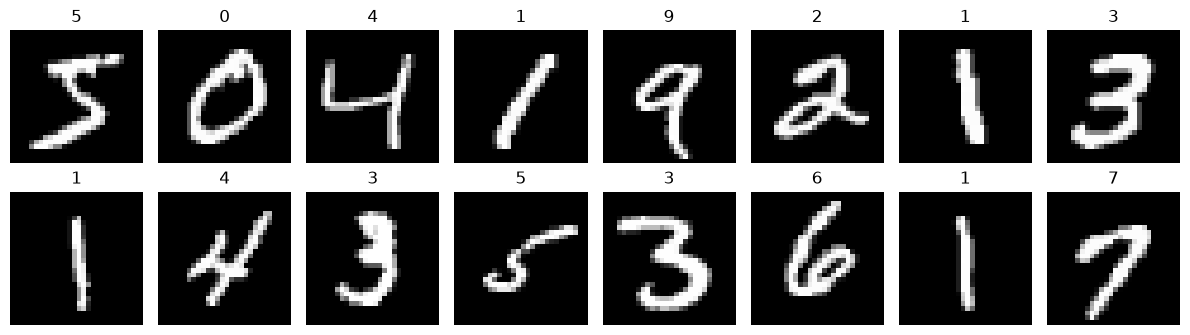

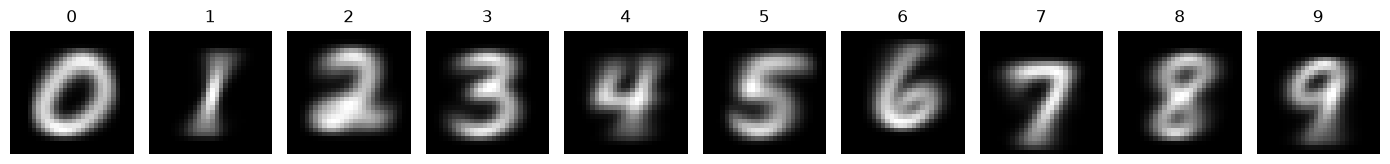

In [17]:
# ================================================================= 1. LOAD
def read_images(path):
    with open(path, "rb") as f:
        magic, n, rows, cols = struct.unpack(">IIII", f.read(16))
        assert magic == 2051, f"{path} is not an IDX image file"
        return np.frombuffer(f.read(), dtype=np.uint8).reshape(n, rows * cols).astype(np.float32)


def read_labels(path):
    with open(path, "rb") as f:
        magic, n = struct.unpack(">II", f.read(8))
        assert magic == 2049, f"{path} is not an IDX label file"
        return np.frombuffer(f.read(), dtype=np.uint8).astype(np.int64)


X_all = read_images(DATA_DIR / "train-images.idx3-ubyte")
y_all = read_labels(DATA_DIR / "train-labels.idx1-ubyte")
X_test = read_images(DATA_DIR / "t10k-images.idx3-ubyte")
y_test = read_labels(DATA_DIR / "t10k-labels.idx1-ubyte")
print("Train:", X_all.shape, " Test:", X_test.shape)
print("Pixel range:", X_all.min(), "-", X_all.max())
print("Class balance (train):\n", pd.Series(y_all).value_counts(normalize=True).sort_index().round(3))

# Look at a few samples
fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))
for ax, img, lab in zip(axes.ravel(), X_all[:16], y_all[:16]):
    ax.imshow(img.reshape(28, 28), cmap="gray")
    ax.set_title(lab)
    ax.axis("off")
plt.tight_layout()
plt.savefig("samples.png")

# Average image per digit (shows what each class looks like on average)
fig, axes = plt.subplots(1, 10, figsize=(14, 2))
for d, ax in enumerate(axes):
    ax.imshow(X_all[y_all == d].mean(axis=0).reshape(28, 28), cmap="gray")
    ax.set_title(d)
    ax.axis("off")
plt.tight_layout()
plt.savefig("mean_digits.png")

In [18]:
# ================================================================ 2. SPLIT
# Split BEFORE fitting anything (scaler, PCA) to avoid data leakage.
# Train -> fit models | Validation -> compare models | Test -> final score only.
X_train, X_val, y_train, y_val = train_test_split(
    X_all, y_all, test_size=0.2, stratify=y_all, random_state=42
)
if N_TRAIN:
    X_train, y_train = X_train[:N_TRAIN], y_train[:N_TRAIN]
print(f"\nTraining on {len(X_train)} images, validating on {len(X_val)}")



Training on 10000 images, validating on 12000


In [19]:
# ====================================================== 3. PREPROCESSING
# (a) Normalize pixels from 0-255 to 0-1
X_train_n, X_val_n, X_test_n = X_train / 255.0, X_val / 255.0, X_test / 255.0


# (b) Optional augmentation: shift images 1 pixel in 4 directions
def augment_shift(X, y):
    imgs = X.reshape(-1, 28, 28)
    Xs, ys = [X], [y]
    for dx, dy in [(1, 0), (-1, 0), (0, 1), (0, -1)]:
        shifted = np.array([shift(im, [dy, dx], cval=0) for im in imgs])
        Xs.append(shifted.reshape(len(X), -1))
        ys.append(y)
    return np.vstack(Xs), np.concatenate(ys)


if AUGMENT:
    X_train_n, y_train = augment_shift(X_train_n, y_train)
    print("After augmentation:", X_train_n.shape)

# (c) Remove constant pixels (always 0 in the border area), learned from training data only
keep = X_train_n.std(axis=0) > 0
print(f"Informative pixels: {keep.sum()} / 784")
X_train_n, X_val_n, X_test_n = X_train_n[:, keep], X_val_n[:, keep], X_test_n[:, keep]


Informative pixels: 675 / 784


Logistic Regression    val acc=0.8829  time=1.4s
KNN (k=3)              val acc=0.9481  time=1.0s
KNN + PCA(50)          val acc=0.9565  time=0.3s
Random Forest          val acc=0.9510  time=1.3s
SVM (RBF) + PCA(50)    val acc=0.9741  time=3.8s

               model  val_accuracy  seconds
SVM (RBF) + PCA(50)      0.974083 3.785957
      KNN + PCA(50)      0.956500 0.278831
      Random Forest      0.951000 1.312062
          KNN (k=3)      0.948083 0.985290
Logistic Regression      0.882917 1.416670


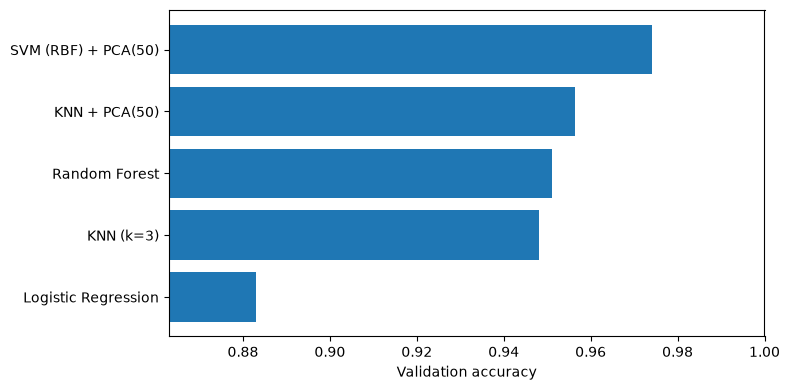

In [20]:
# ================================================================ 4. MODELS
models = {
    "Logistic Regression": make_pipeline(StandardScaler(),
                                         LogisticRegression(max_iter=200)),
    "KNN (k=3)": KNeighborsClassifier(n_neighbors=3, n_jobs=-1),
    "KNN + PCA(50)": make_pipeline(PCA(n_components=50, random_state=42),
                                   KNeighborsClassifier(n_neighbors=3, n_jobs=-1)),
    "Random Forest": RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42),
    "SVM (RBF) + PCA(50)": make_pipeline(PCA(n_components=50, random_state=42),
                                         SVC(kernel="rbf", C=5, gamma="scale")),
}

results, fitted = [], {}
for name, model in models.items():
    t0 = time.time()
    model.fit(X_train_n, y_train)
    preds = model.predict(X_val_n)
    acc = accuracy_score(y_val, preds)
    results.append((name, acc, time.time() - t0))
    fitted[name] = model
    print(f"{name:22s} val acc={acc:.4f}  time={time.time() - t0:.1f}s")

# ============================================================== 5. COMPARE
res = pd.DataFrame(results, columns=["model", "val_accuracy", "seconds"])
res = res.sort_values("val_accuracy", ascending=False).reset_index(drop=True)
print("\n", res.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(res["model"][::-1], res["val_accuracy"][::-1])
ax.set_xlim(res["val_accuracy"].min() - 0.02, 1.0)
ax.set_xlabel("Validation accuracy")
plt.tight_layout()
plt.savefig("model_comparison.png")



Best model: SVM (RBF) + PCA(50)
Test accuracy: 0.9740

Per-digit accuracy: {0: np.float64(0.99), 1: np.float64(0.994), 2: np.float64(0.971), 3: np.float64(0.972), 4: np.float64(0.973), 5: np.float64(0.969), 6: np.float64(0.979), 7: np.float64(0.963), 8: np.float64(0.966), 9: np.float64(0.961)}


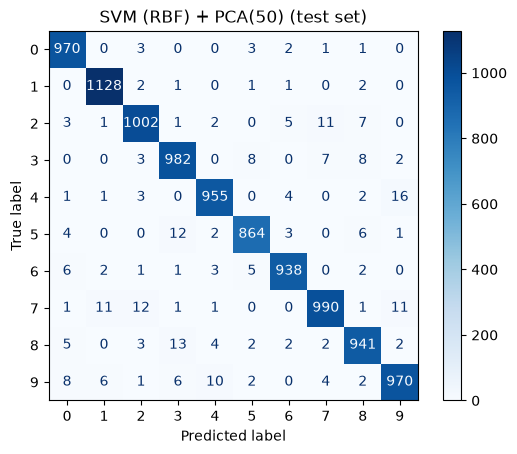

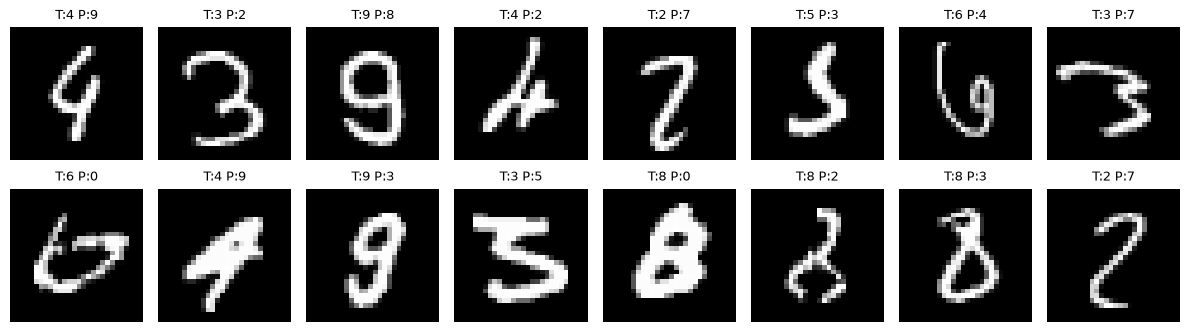

In [21]:
# ======================================================== 6. FINAL TEST SCORE
# Only the single best model (chosen on validation) is scored on the test set.
best_name = res.loc[0, "model"]
best_model = fitted[best_name]
test_preds = best_model.predict(X_test_n)
print(f"\nBest model: {best_name}")
print(f"Test accuracy: {accuracy_score(y_test, test_preds):.4f}")

cm = confusion_matrix(y_test, test_preds)
ConfusionMatrixDisplay(cm).plot(cmap="Blues")
plt.title(f"{best_name} (test set)")
plt.savefig("confusion_matrix.png")

# Per-digit accuracy
per_digit = cm.diagonal() / cm.sum(axis=1)
print("\nPer-digit accuracy:", {d: round(a, 3) for d, a in enumerate(per_digit)})

# Look at mistakes
wrong = np.where(test_preds != y_test)[0][:16]
fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))
for ax, i in zip(axes.ravel(), wrong):
    ax.imshow(X_test[i].reshape(28, 28), cmap="gray")
    ax.set_title(f"T:{y_test[i]} P:{test_preds[i]}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.savefig("errors.png")
plt.show()